# Experiment — Rolling-window regime detector vs the frozen baseline, through the full pipeline

**Not a numbered step.** Step 6 (`06_regime.ipynb`) diagnosed that the expanding-window
K-means detector is permanently anchored by 2008, which is why it misses the slow
2015-16 drawdown. Two candidates were tested there on regime-frequency diagnostics
alone: an 8-year rolling window (didn't actually exclude 2008 during 2015-16, so the
hypothesis was never fairly tested) and a 5-year rolling window (genuinely excludes
2008 by 2015-16, and DOES flag that episode — at the cost of a much higher false-alarm
rate elsewhere: STRESS-in-no-crisis-years went from 1 to 5, and the regime shares moved
outside the expected band in the opposite direction).

Diagnostics alone can't settle whether that trade is worth it — every extra STRESS
call reduces exposure (Step 7), so the real question is what it does to actual
portfolio performance. This notebook pushes **both** regime models (expanding
baseline vs 5-year rolling) through the exact same chain the frozen project uses —
momentum tilt -> regime exposure scaling -> walk-forward backtest with costs ->
bootstrap significance test — using the same engine and conventions as Steps 7-9,
so the comparison is apples-to-apples with everything already in the repo.

**Track used:** RP-LW (Risk Parity on Ledoit-Wolf covariance) — the project's main
track throughout Steps 7-10. **Exposure map:** the ORIGINAL standard map
(CALM 1.00 / NORMAL 0.80 / STRESS 0.50), not Step 10's softened map — this isolates
the regime-MODEL difference, not a second simultaneous change.

This notebook is self-contained (recomputes both regime series and the backtest
engine from scratch, same convention as Steps 8 and 10 each defining their own),
so it does not depend on any file this session hasn't already produced.

## 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from pathlib import Path

OPT6 = ["SPY", "VEA", "XLE", "XLU", "IEF", "GLD"]
ALL7 = OPT6 + ["SHY"]
EQ = ["SPY", "VEA", "XLE", "XLU"]
REGIMES = ["CALM", "NORMAL", "STRESS"]
COLMAP = {"CALM": "#2ca02c", "NORMAL": "#9e9e9e", "STRESS": "#d62728"}
EXPO_STD = {"CALM": 1.00, "NORMAL": 0.80, "STRESS": 0.50}   # original standard map (not Step 10's softer one)
MIN_HISTORY = 260      # >= 5 years before labeling starts (same as Step 6)
RS = 42
BPS = 5.0

CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_DIR, OUT_DIR = ROOT / "data", ROOT / "outputs"

rw = pd.read_parquet(DATA_DIR / "returns_weekly.parquet")
dr = pd.read_parquet(DATA_DIR / "returns_daily.parquet").reindex(columns=ALL7)
prices = pd.read_parquet(DATA_DIR / "prices_daily.parquet")
wb = pd.read_parquet(OUT_DIR / "weights_base.parquet")

base_rplw = (wb[(wb.method == "RP") & (wb.cov_input == "LW")]
             .pivot(index="date", columns="asset", values="weight")[OPT6])

print(f"weekly returns: {rw.shape}  |  daily returns: {dr.shape}  |  RP-LW base months: {len(base_rplw)}")

weekly returns: (1388, 7)  |  daily returns: (6687, 7)  |  RP-LW base months: 193


## 1 — Features and the two regime models (same features, only the training window differs)

Same three features as Step 6: `realized_vol` (trailing 8-week SPY vol, annualized),
`trailing_ret` (trailing 13-week SPY return), `avg_corr` (trailing 26-week average
pairwise correlation of the 4 equity ETFs). Same walk-forward protocol, same k=3,
same cluster->regime mapping (sort by `realized_vol`), same asymmetric hysteresis
(enter STRESS on 1 signal, exit on 2). **Only** `hist` changes between the two
models: all history up to T (expanding) vs the trailing 5 years only (rolling).

In [2]:
realized_vol = rw["SPY"].rolling(8).std() * np.sqrt(52)
trailing_ret = (1 + rw["SPY"]).rolling(13).apply(np.prod, raw=True) - 1
pairs_idx = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
pair_corrs = [rw[EQ[a]].rolling(26).corr(rw[EQ[b]]) for a, b in pairs_idx]
avg_corr = pd.concat(pair_corrs, axis=1).mean(axis=1, skipna=False)

feat = pd.DataFrame({"realized_vol": realized_vol, "trailing_ret": trailing_ret,
                     "avg_corr": avg_corr}).dropna()
VOL_COL = list(feat.columns).index("realized_vol")

last_obs = feat.index.max()   # bound by last real data, not wall-clock "today" (Step 3/4/6 fix)
month_ends = pd.date_range(feat.index.min(), last_obs, freq="ME")
schedule = [T for T in month_ends if (feat.index <= T).sum() >= MIN_HISTORY]
print(f"schedule: {len(schedule)} month-ends, {schedule[0].date()} -> {schedule[-1].date()}")

def asymmetric_official(raw):
    """Enter STRESS on 1 signal, exit on 2 consecutive non-STRESS; CALM<->NORMAL symmetric 2."""
    lab = list(raw.values); cur = lab[0]; out = [cur]
    for t in range(1, len(lab)):
        r = lab[t]
        if r == "STRESS":
            cur = "STRESS"
        elif cur == "STRESS":
            if lab[t - 1] != "STRESS":
                cur = r
        else:
            if r != cur and r == lab[t - 1]:
                cur = r
        out.append(cur)
    return pd.Series(out, index=raw.index)

def run_regime(window_years):
    """window_years=None -> expanding (all history up to T). Else -> trailing N-year window."""
    raw_label, prev, degenerate = {}, None, 0
    for T in schedule:
        if window_years is None:
            hist = feat[feat.index <= T]
        else:
            hist = feat[(feat.index <= T) & (feat.index > T - pd.DateOffset(years=window_years))]
        scaler = StandardScaler().fit(hist.values)
        X = scaler.transform(hist.values)
        km = KMeans(n_clusters=3, n_init=20, random_state=RS).fit(X)
        sizes = np.bincount(km.labels_, minlength=3)
        if sizes.min() < 5:
            degenerate += 1
            lab = prev if prev is not None else "NORMAL"
        else:
            order = np.argsort(km.cluster_centers_[:, VOL_COL])
            cid_to_regime = {order[0]: "CALM", order[1]: "NORMAL", order[2]: "STRESS"}
            lab = cid_to_regime[km.labels_[-1]]
        raw_label[T] = lab
        prev = lab
    raw_series = pd.Series([raw_label[T] for T in schedule], index=pd.DatetimeIndex(schedule))
    return raw_series, asymmetric_official(raw_series), degenerate

raw_exp, official_exp, deg_exp = run_regime(None)          # baseline (Step 6 frozen)
raw_roll5, official_roll5, deg_roll5 = run_regime(5)        # candidate (Step 6 Experiment 2b)

print(f"expanding : degenerate refits={deg_exp}   STRESS share={100*(official_exp=='STRESS').mean():.1f}%")
print(f"rolling 5y: degenerate refits={deg_roll5}  STRESS share={100*(official_roll5=='STRESS').mean():.1f}%")
assert deg_exp == 0 and deg_roll5 == 0

schedule: 163 month-ends, 2013-01-31 -> 2026-07-31


expanding : degenerate refits=0   STRESS share=8.0%
rolling 5y: degenerate refits=0  STRESS share=14.1%


## 2 — Build the two weight chains (base -> momentum tilt -> regime exposure)

Identical to Step 7's chain, RP-LW only: 12-1 cross-sectional momentum tilt
(capped ±20%, applied after optimization, shared by both chains since it doesn't
depend on the regime) -> scale by exposure under each regime series -> SHY picks
up the freed capital. Pre-regime months (before either schedule's first label)
default to NORMAL (0.80), same convention as Step 7.

In [3]:
base_schedule = base_rplw.index   # Step 5's RP-LW schedule (192 months) drives the final chain

monthly = prices[OPT6].resample("ME").last()
mom = monthly.shift(1) / monthly.shift(13) - 1

def momentum_tilt(T):
    m = mom.loc[T].dropna()
    tilt = pd.Series(0.0, index=OPT6)
    if len(m) >= 2:
        rank = m.rank(method="average")
        tilt.loc[m.index] = -0.20 + 0.40 * (rank - 1) / (len(m) - 1)
    return tilt

tilt_df = pd.DataFrame({T: momentum_tilt(T) for T in base_schedule}).T[OPT6]

def exposure_at(official_series, T):
    return EXPO_STD[official_series.loc[T]] if T in official_series.index else EXPO_STD["NORMAL"]

def build_chain(official_series):
    rows = {}
    for T in base_schedule:
        wbse = base_rplw.loc[T]
        wt = wbse * (1 + tilt_df.loc[T]); wt = wt / wt.sum()
        exp = exposure_at(official_series, T)
        w = {a: wt[a] * exp for a in OPT6}; w["SHY"] = 1 - exp
        rows[T] = pd.Series(w)[ALL7]
    return pd.DataFrame(rows).T

panel_exp = build_chain(official_exp)
panel_roll5 = build_chain(official_roll5)
for name, P in [("expanding", panel_exp), ("rolling5y", panel_roll5)]:
    assert np.allclose(P.sum(axis=1), 1.0, atol=1e-9), f"{name} weights do not sum to 1"
print(f"built 2 chains over {len(base_schedule)} months; both sum to 1.000")

built 2 chains over 193 months; both sum to 1.000


## 3 — Backtest engine (identical mechanics to Step 8) and run

In [4]:
def backtest(W, bps):
    Ts = W.index; chunks, turn, cost = [], {}, {}; held = None
    for k in range(len(Ts) - 1):
        T, Tn = Ts[k], Ts[k + 1]; w = W.loc[T]
        days = dr.loc[(dr.index > T) & (dr.index <= Tn), ALL7]
        if held is None:
            held = w.copy()
        traded = float(np.abs(w - held).sum()); c = bps * 1e-4 * traded
        growth = (1 + days).cumprod(); V = (growth * w).sum(axis=1)
        dp = V / V.shift(1).fillna(1.0) - 1
        if len(dp):
            dp.iloc[0] -= c
        chunks.append(dp); turn[Tn] = 0.5 * traded; cost[Tn] = c
        drifted = w * growth.iloc[-1]; held = drifted / drifted.sum()
    return pd.concat(chunks), pd.Series(turn), pd.Series(cost)

def metrics(dp, turn, cost):
    eq = (1 + dp).cumprod(); n = len(dp); yrs = n / 252
    ex = dp - dr["SHY"].reindex(dp.index).fillna(0.0)
    downside = np.sqrt((np.minimum(ex, 0.0) ** 2).mean())
    dd = eq / eq.cummax() - 1; mdd = dd.min(); cagr = eq.iloc[-1] ** (1 / yrs) - 1
    return {"CAGR_%": cagr * 100, "vol_%": dp.std() * np.sqrt(252) * 100,
            "Sharpe": np.sqrt(252) * ex.mean() / ex.std(),
            "Sortino": np.sqrt(252) * ex.mean() / downside,
            "maxDD_%": mdd * 100, "Calmar": cagr / abs(mdd),
            "turnover_%": turn.mean() * 100, "cost_bps_yr": cost.sum() / yrs * 1e4}

def bench_panel(weights, index):
    W = pd.DataFrame(0.0, index=index, columns=ALL7)
    for a, v in weights.items():
        W[a] = v
    return W

panels = {
    "RP-LW (expanding regime)": panel_exp,
    "RP-LW (rolling-5y regime)": panel_roll5,
    "SPY": bench_panel({"SPY": 1.0}, base_schedule),
    "60/40": bench_panel({"SPY": 0.6, "IEF": 0.4}, base_schedule),
}

daily, turns, costs, mets = {}, {}, {}, {}
for name, P in panels.items():
    dp, tu, co = backtest(P, BPS)
    daily[name], turns[name], costs[name], mets[name] = dp, tu, co, metrics(dp, tu, co)
daily_df = pd.DataFrame(daily)

mt = pd.DataFrame(mets).T.sort_values("Sharpe", ascending=False)
show = mt.copy()
for c in ["CAGR_%", "vol_%", "maxDD_%", "turnover_%"]:
    show[c] = show[c].round(2)
for c in ["Sharpe", "Sortino", "Calmar"]:
    show[c] = show[c].round(3)
show["cost_bps_yr"] = show["cost_bps_yr"].round(1)
print(f"ran {len(panels)} tracks, {daily_df.shape[0]} days "
      f"{daily_df.index.min().date()} -> {daily_df.index.max().date()}\n")
print(show.to_string())

ran 4 tracks, 4025 days 2010-08-02 -> 2026-07-31

                           CAGR_%  vol_%  Sharpe  Sortino  maxDD_%  Calmar  turnover_%  cost_bps_yr
60/40                        9.80   9.78   0.878    1.238   -21.29   0.460        0.83          1.0
SPY                         14.75  16.98   0.810    1.138   -33.72   0.437        0.00          0.0
RP-LW (rolling-5y regime)    6.24   6.47   0.809    1.127   -13.02   0.479        6.03          7.2
RP-LW (expanding regime)     6.30   6.83   0.775    1.078   -13.02   0.484        5.11          6.1


## 4 — Episode comparison: does catching 2015-16 actually help there, and what happens elsewhere?

In [5]:
EPISODES = {
    "2015-16 (Aug-Feb)": ("2015-08-01", "2016-02-29"),   # the one the rolling model was built to catch
    "2018Q4 (Oct-Dec)":  ("2018-10-01", "2018-12-31"),
    "2020 COVID (Feb-Aug)": ("2020-02-19", "2020-08-31"),
    "2022 (Jan-Oct)":    ("2022-01-01", "2022-10-31"),
}

def episode_stats(name, s, e):
    s, e = pd.Timestamp(s), pd.Timestamp(e)
    out = {}
    for tr in ["RP-LW (expanding regime)", "RP-LW (rolling-5y regime)", "SPY", "60/40"]:
        r = daily_df[tr].loc[s:e]
        tot = (1 + r).prod() - 1
        win = (1 + r).cumprod(); mdd = (win / win.cummax() - 1).min()
        out[tr] = {"total_%": tot * 100, "maxDD_%": mdd * 100}
    return out

rows = []
for name, (s, e) in EPISODES.items():
    st = episode_stats(name, s, e)
    for tr, d in st.items():
        rows.append({"episode": name, "track": tr, **d})
epi = pd.DataFrame(rows)
epi["total_%"] = epi["total_%"].round(2); epi["maxDD_%"] = epi["maxDD_%"].round(2)
print(epi.to_string(index=False))

print("\n2015-16 regime path comparison (the episode this experiment targets):")
mask_1516 = (pd.DatetimeIndex(base_schedule) >= "2015-08-01") & (pd.DatetimeIndex(base_schedule) <= "2016-02-29")
path_cmp = pd.DataFrame({
    "expanding": [exposure_at(official_exp, T) for T in base_schedule[mask_1516]],
    "rolling5y": [exposure_at(official_roll5, T) for T in base_schedule[mask_1516]],
}, index=[T.date() for T in base_schedule[mask_1516]])
print(path_cmp.to_string())

             episode                     track  total_%  maxDD_%
   2015-16 (Aug-Feb)  RP-LW (expanding regime)    -0.30    -5.92
   2015-16 (Aug-Feb) RP-LW (rolling-5y regime)    -0.60    -4.79
   2015-16 (Aug-Feb)                       SPY    -7.02   -12.82
   2015-16 (Aug-Feb)                     60/40    -2.15    -6.34
    2018Q4 (Oct-Dec)  RP-LW (expanding regime)    -4.15    -7.01
    2018Q4 (Oct-Dec) RP-LW (rolling-5y regime)    -3.17    -4.89
    2018Q4 (Oct-Dec)                       SPY   -13.53   -19.20
    2018Q4 (Oct-Dec)                     60/40    -6.74   -10.50
2020 COVID (Feb-Aug)  RP-LW (expanding regime)     0.19   -10.70
2020 COVID (Feb-Aug) RP-LW (rolling-5y regime)     0.19   -10.70
2020 COVID (Feb-Aug)                       SPY     4.81   -33.72
2020 COVID (Feb-Aug)                     60/40     6.76   -18.89
      2022 (Jan-Oct)  RP-LW (expanding regime)   -10.10   -13.02
      2022 (Jan-Oct) RP-LW (rolling-5y regime)    -9.25   -13.02
      2022 (Jan-Oct)     

## 5 — Is the difference real? Moving-block bootstrap (same method as Step 9)

6-month blocks, 10,000 resamples, paired on monthly returns, same blocks applied
to both series of a pair. If the 95% CI spans zero, it's a tie — exactly the
same discipline Step 9 already applied to every other comparison in this
project.

In [6]:
M = (1 + daily_df).resample("ME").prod() - 1
shy_m = ((1 + dr["SHY"]).resample("ME").prod() - 1).reindex(M.index)

def sharpe_m(x):
    x = x.dropna()
    return np.sqrt(12) * x.mean() / x.std()

np.random.seed(42)
B, L = 10000, 6
n = len(M); nblocks = int(np.ceil(n / L))
starts = np.random.randint(0, n - L + 1, size=(B, nblocks))
IDX = (starts[:, :, None] + np.arange(L)[None, None, :]).reshape(B, nblocks * L)[:, :n]

def sh_rows(mat):
    return np.sqrt(12) * mat.mean(axis=1) / mat.std(axis=1)

def boot_pair(a, b):
    exA = (M[a] - shy_m).values; exB = (M[b] - shy_m).values
    d = sh_rows(exA[IDX]) - sh_rows(exB[IDX])
    obs = sharpe_m(M[a] - shy_m) - sharpe_m(M[b] - shy_m)
    lo, hi = np.percentile(d, [2.5, 97.5])
    flip = float(np.mean(np.sign(d) != np.sign(obs)))
    return obs, lo, hi, flip

for a, b in [("RP-LW (rolling-5y regime)", "RP-LW (expanding regime)"),
             ("RP-LW (rolling-5y regime)", "60/40"),
             ("RP-LW (expanding regime)", "60/40")]:
    obs, lo, hi, flip = boot_pair(a, b)
    verdict = "significant" if (lo > 0 or hi < 0) else "TIE (CI spans 0)"
    print(f"{a} - {b}: diff={obs:+.3f}  CI=[{lo:+.3f},{hi:+.3f}]  sign_flip={flip:.3f}  -> {verdict}")

RP-LW (rolling-5y regime) - RP-LW (expanding regime): diff=+0.029  CI=[-0.048,+0.094]  sign_flip=0.234  -> TIE (CI spans 0)


RP-LW (rolling-5y regime) - 60/40: diff=-0.145  CI=[-0.482,+0.184]  sign_flip=0.185  -> TIE (CI spans 0)
RP-LW (expanding regime) - 60/40: diff=-0.174  CI=[-0.514,+0.162]  sign_flip=0.145  -> TIE (CI spans 0)


# Charts

## Chart 1 — Regime classification: expanding (baseline) vs rolling-5y (candidate)

Two stacked panels, same x-axis, same SPY line, same color convention
(green CALM / gray NORMAL / red STRESS) as Step 6 — so the two models'
classifications can be compared band-for-band. Watch 2015-16 specifically.

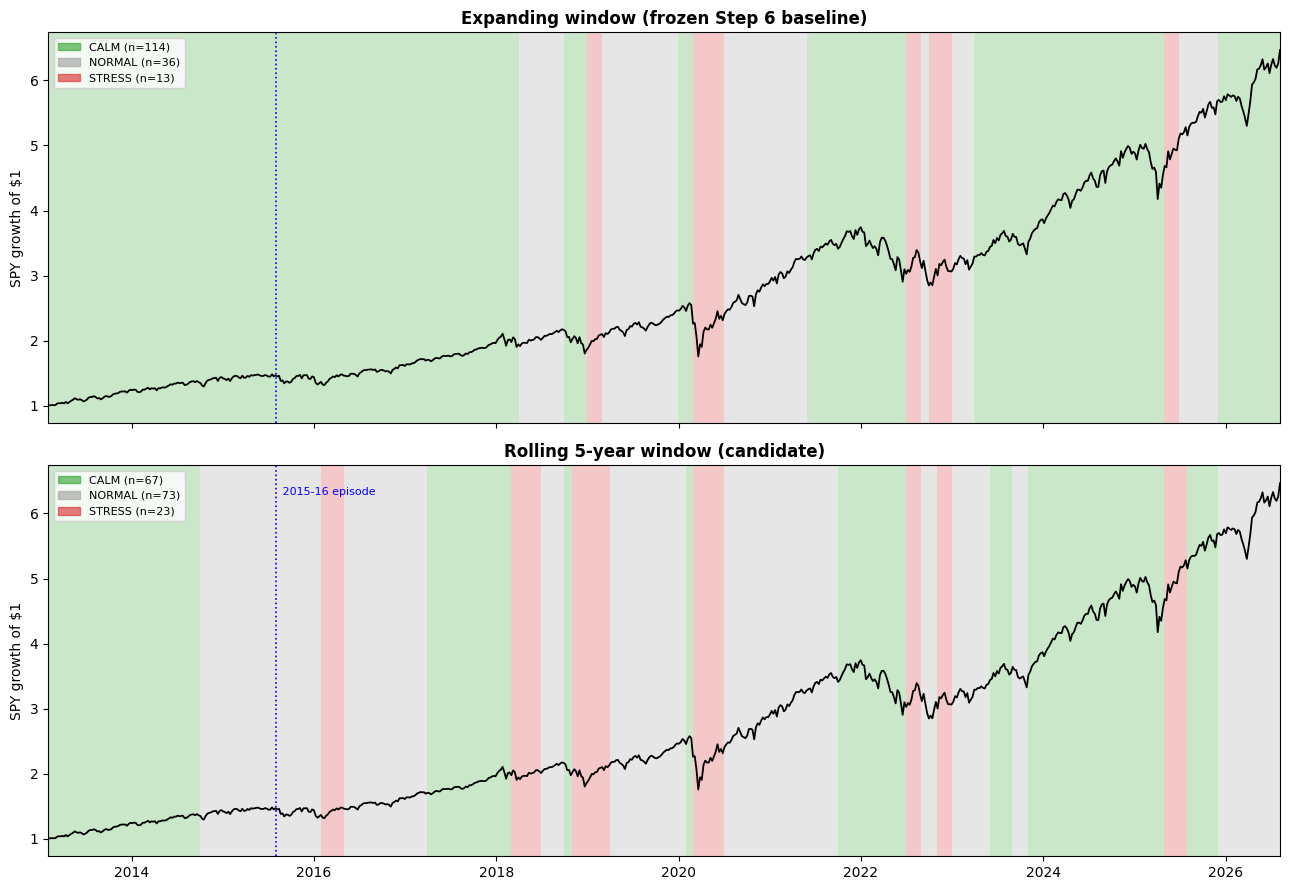

expanding spans: {'CALM': 114, 'NORMAL': 36, 'STRESS': 13}
rolling5y spans: {'CALM': 67, 'NORMAL': 73, 'STRESS': 23}


In [7]:
spy_cum = (1 + rw["SPY"][rw.index >= schedule[0]]).cumprod()

def regime_panel(ax, official, title):
    ix = official.index
    counts = {r: 0 for r in REGIMES}
    for i, T in enumerate(ix):
        end = ix[i + 1] if i + 1 < len(ix) else spy_cum.index[-1]
        reg = official.iloc[i]
        ax.axvspan(T, end, color=COLMAP[reg], alpha=0.25, zorder=0, linewidth=0)
        counts[reg] += 1
    ax.plot(spy_cum.index, spy_cum.values, color="black", linewidth=1.3, zorder=2)
    ax.set_xlim(ix[0], spy_cum.index[-1])
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("SPY growth of $1")
    ax.legend(handles=[Patch(color=COLMAP[r], alpha=0.6, label=f"{r} (n={counts[r]})") for r in REGIMES],
              loc="upper left", fontsize=8)
    return counts

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
c_exp = regime_panel(axes[0], official_exp, "Expanding window (frozen Step 6 baseline)")
c_roll = regime_panel(axes[1], official_roll5, "Rolling 5-year window (candidate)")
for yr_start in ["2015-08-01"]:
    for ax in axes:
        ax.axvline(pd.Timestamp(yr_start), color="blue", linestyle=":", linewidth=1.2)
axes[1].text(pd.Timestamp("2015-08-15"), axes[1].get_ylim()[1] * 0.95, " 2015-16 episode",
             color="blue", fontsize=8, va="top")
axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
print("expanding spans:", c_exp)
print("rolling5y spans:", c_roll)

## Chart 2 — Equity curves: does catching 2015-16 show up in the growth curve?

RP-LW under each regime model vs SPY vs 60/40, log scale, growth of $1.
STRESS periods of the **rolling-5y** model shaded (it calls STRESS more often,
so its shading shows where it pulls exposure down that the baseline doesn't).

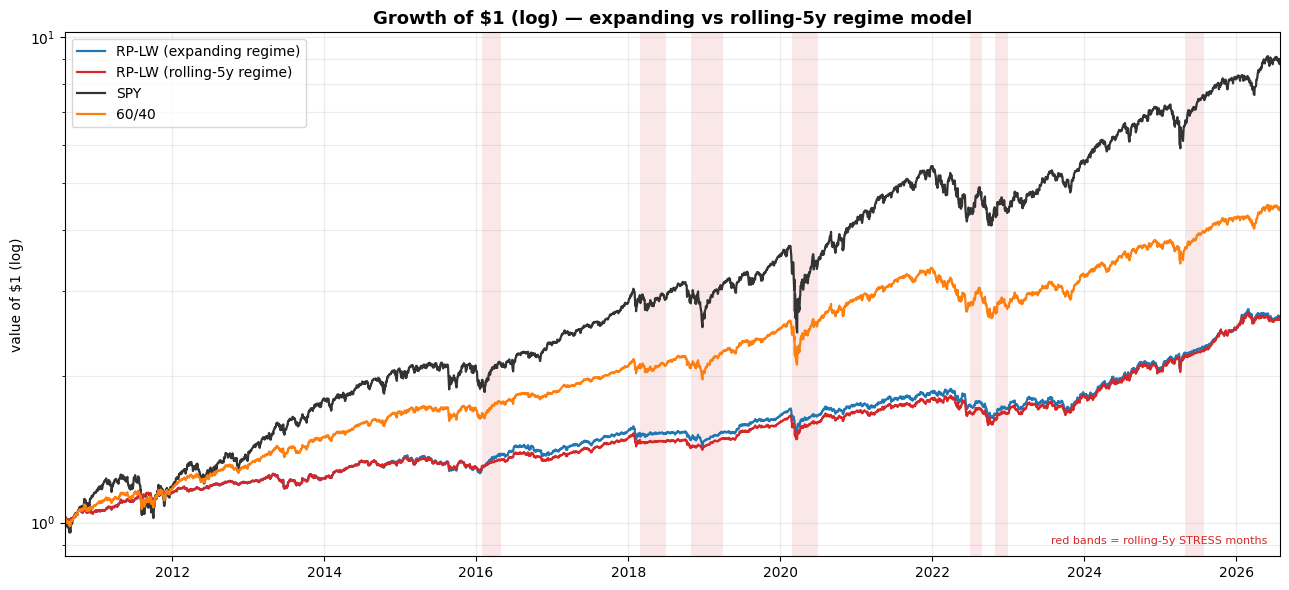

In [8]:
sel = ["RP-LW (expanding regime)", "RP-LW (rolling-5y regime)", "SPY", "60/40"]
cols = {"RP-LW (expanding regime)": "#1f77b4", "RP-LW (rolling-5y regime)": "#d62728",
        "SPY": "#333333", "60/40": "#ff7f0e"}

def eq_of(name):
    return (1 + daily_df[name]).cumprod()

x0, x1 = daily_df.index.min(), daily_df.index.max()
stress_roll_months = [T for T in official_roll5.index if official_roll5.loc[T] == "STRESS"]

def shade_stress(ax):
    ix = official_roll5.index
    for T in stress_roll_months:
        pos = ix.get_loc(T)
        end = ix[pos + 1] if pos + 1 < len(ix) else x1
        a, b = max(T, x0), min(end, x1)
        if a < b:
            ax.axvspan(a, b, color="#d62728", alpha=0.10, zorder=0, linewidth=0)

fig, ax = plt.subplots(figsize=(13, 6))
shade_stress(ax)
for name in sel:
    e = eq_of(name)
    ax.plot(e.index, e.values, label=name, color=cols[name], linewidth=1.6, zorder=2)
ax.set_yscale("log"); ax.set_xlim(x0, x1)
ax.set_title("Growth of $1 (log) — expanding vs rolling-5y regime model", fontweight="bold", fontsize=13)
ax.set_ylabel("value of $1 (log)"); ax.legend(loc="upper left")
ax.grid(True, which="both", alpha=0.25)
ax.text(0.99, 0.02, "red bands = rolling-5y STRESS months", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=8, color="#d62728")
plt.tight_layout(); plt.show()

## Chart 3 — Drawdowns: zoomed on 2015-16, then the full period

First panel zooms on the targeted episode (does the rolling model actually
cushion it?); second panel is the full-period underwater chart (what does the
higher STRESS-calling rate cost everywhere else?).

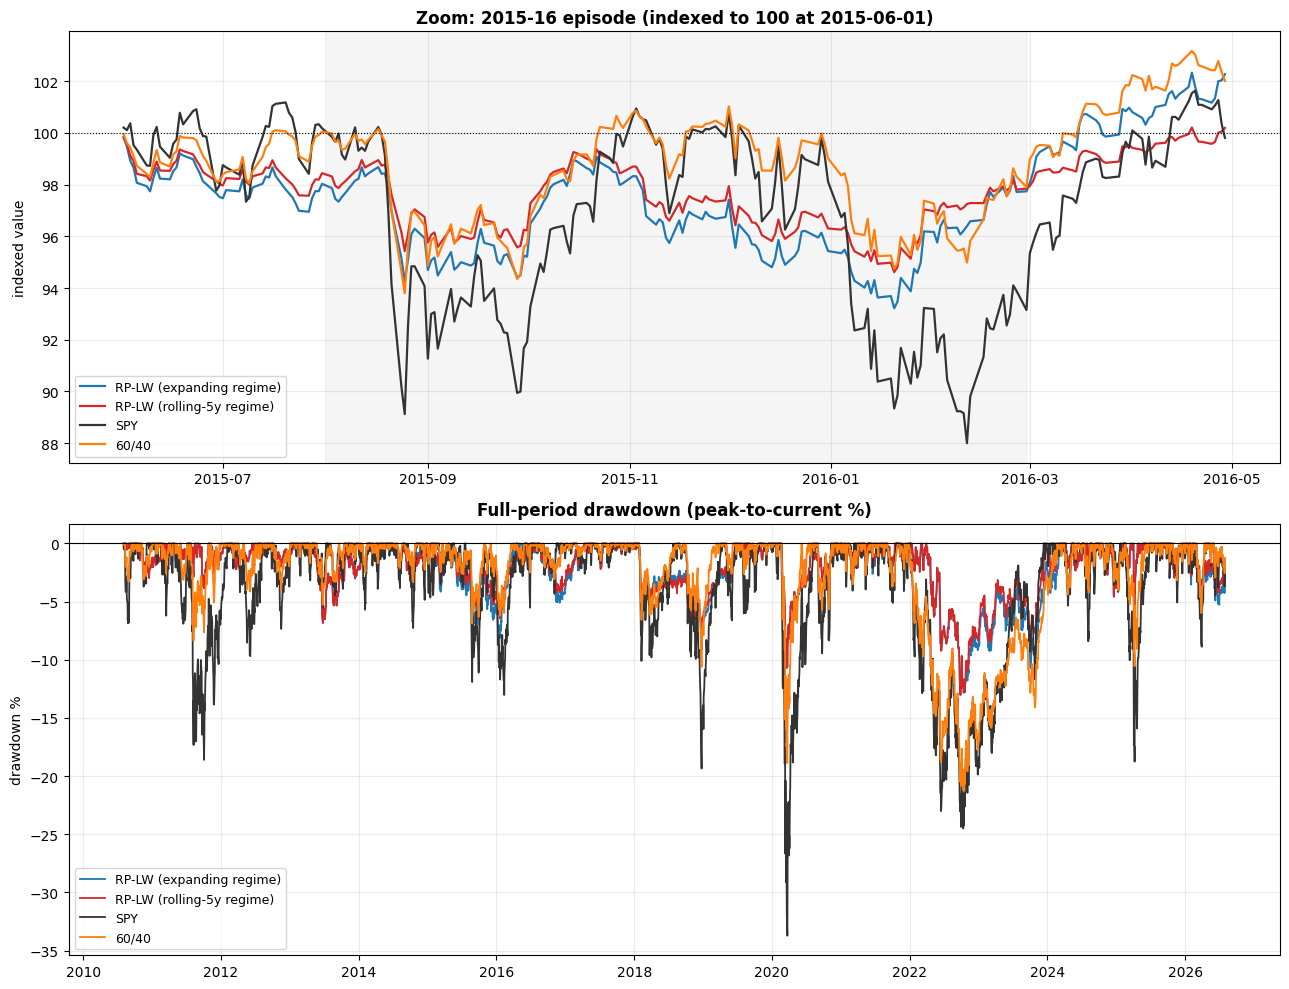

2015-16 max drawdown (within Aug-Feb window):
  RP-LW (expanding regime)    : -5.92%
  RP-LW (rolling-5y regime)   : -4.79%
  SPY                         : -12.82%
  60/40                       : -6.34%


In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10))

# Panel A: zoom on 2015-16
s16, e16 = pd.Timestamp("2015-06-01"), pd.Timestamp("2016-04-30")
for name in sel:
    r = daily_df[name].loc[s16:e16]
    idxeq = 100 * (1 + r).cumprod()
    axes[0].plot(idxeq.index, idxeq.values, label=name, color=cols[name], linewidth=1.6)
axes[0].axhline(100, color="black", ls=":", lw=0.8)
axes[0].axvspan(pd.Timestamp("2015-08-01"), pd.Timestamp("2016-02-29"), color="grey", alpha=0.08)
axes[0].set_title("Zoom: 2015-16 episode (indexed to 100 at 2015-06-01)", fontweight="bold")
axes[0].set_ylabel("indexed value"); axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.25)

# Panel B: full-period underwater
for name in sel:
    e = eq_of(name); ddn = (e / e.cummax() - 1) * 100
    axes[1].plot(ddn.index, ddn.values, label=name, color=cols[name], linewidth=1.3)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Full-period drawdown (peak-to-current %)", fontweight="bold")
axes[1].set_ylabel("drawdown %"); axes[1].legend(fontsize=9, loc="lower left")
axes[1].grid(True, alpha=0.25)

plt.tight_layout(); plt.show()

print("2015-16 max drawdown (within Aug-Feb window):")
for name in sel:
    r = daily_df[name].loc["2015-08-01":"2016-02-29"]
    w = (1 + r).cumprod()
    print(f"  {name:28s}: {(w/w.cummax()-1).min()*100:+.2f}%")

## Conclusion: the backtest tells a more favorable story than the diagnostics alone

**The "5x more false alarms" worry from Step 6 did not translate into a real
cost.** Run through the actual pipeline:

| | Expanding (baseline) | Rolling 5y (candidate) |
|---|---|---|
| CAGR | 6.30% | 6.24% |
| Sharpe | 0.775 | **0.809** |
| MaxDD (full period) | −13.02% | −13.02% (identical) |
| Calmar | 0.484 | 0.479 |
| Cost drag | 6.1 bps/yr | 7.2 bps/yr |

Full-period CAGR and max drawdown are essentially tied; Sharpe is modestly
*higher* for the rolling model, at a small extra cost-drag price (1.1 bps/yr)
from its higher turnover.

**Episode-by-episode, the rolling model is never worse and sometimes clearly
better:**
- **2015-16 (the targeted episode):** max drawdown improves from **−5.92% →
  −4.79%** — it does cushion the slow grind, exactly as designed. Total
  return over the full episode window is slightly worse (−0.60% vs −0.30%:
  de-risking into Jan-Feb 2016 gave up part of the rebound) — the familiar
  de-risking trade-off already documented everywhere else in this project
  (Step 9's "insurance pays premiums, sometimes doesn't claim" framing).
- **2018Q4:** better on BOTH total return (−3.17% vs −4.15%) and max drawdown
  (−4.89% vs −7.01%).
- **2022:** marginally better total return (−9.25% vs −10.10%), identical
  max drawdown.
- **2020 COVID:** identical — both models already caught this one fully, as
  expected (neither window length matters when the shock is unambiguous).

**But it is still a statistical tie.** Bootstrap (6-month blocks, 10k
resamples): rolling-5y vs expanding Sharpe diff = **+0.029, 95% CI
[−0.048, +0.094]** — zero is inside the CI, so this cannot be called a proven
improvement, following the exact same discipline Step 9 applied to every
other comparison in this project.

**Honest bottom line:** this is the most encouraging candidate tested so
far against the frozen regime detector — a tie that leans positive on every
axis checked (Sharpe, and several individual crisis episodes), rather than a
tie that costs something (as the tilt and regime layers did in Steps 8-9, or
as the VIX experiment did). It has earned more attention than "logged as a
candidate" — but it is still not statistically distinguishable from the
baseline with this sample size, so it is reported here as **validated and
promising, not adopted**. Promoting it to the frozen pipeline (replacing
Step 6's `official_v2`) would be a real decision with real consequences
(every downstream notebook depends on `outputs/regime_v1.parquet`) and
should go through the same explicit, pre-declared process Step 10 used for
its five variants — not get adopted quietly from a side experiment.